<a href="https://colab.research.google.com/github/hayetmece/machine-learning-_Salary-Prediction/blob/main/salary_prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# توقع الرواتب (Salary Prediction)


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

SEED = 42
rng = np.random.default_rng(SEED)
N = 500
SAL_MIN, SAL_MAX = 60000, 200000

## 1) توليد الداتا (500 سطر)

In [2]:
experience  = rng.integers(0, 21, N)     # سنوات الخبرة 0..20
education   = rng.integers(1, 5, N)      # 1=ثانوي 2=ليسانس 3=ماستر 4=دكتوراه
age         = np.clip(22 + experience + rng.integers(0, 8, N), 22, 65)
skill_score = rng.integers(1, 11, N)     # تقييم المهارات 1..10

salary = (
    60000
    + experience * 3800
    + education * 9000
    + skill_score * 3500
    + rng.normal(0, 8000, N)             # ضوضاء عشوائية
)
salary = np.clip(salary, SAL_MIN, SAL_MAX).round().astype(int)

df = pd.DataFrame({
    "experience": experience,
    "education": education,
    "age": age,
    "skill_score": skill_score,
    "salary": salary,
})
print(df.shape)
df.head(10)

(500, 5)


,experience,education,age,skill_score,salary
0,1,1,29,6,87862
1,16,3,43,3,165695
2,13,4,39,3,156177
3,9,4,38,4,141938
4,9,2,32,6,132351
5,18,2,47,3,158685
6,1,3,29,10,130735
7,14,1,40,5,131702
8,4,2,31,9,116367
9,1,1,27,7,106137


In [ ]:
df.describe().T[["min", "max", "mean"]]

## 2) رسم الداتا

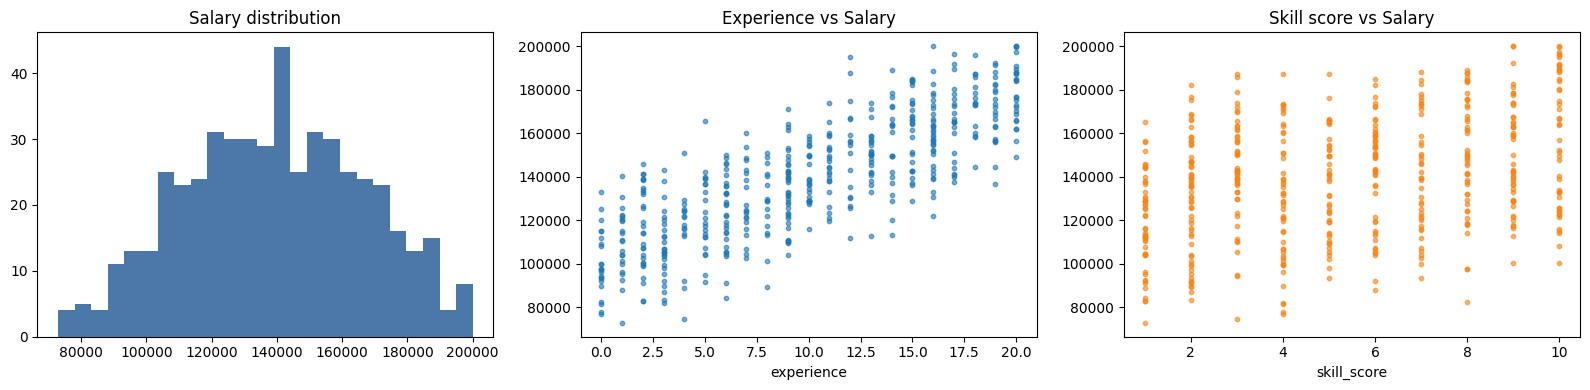

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

axes[0].hist(df["salary"], bins=25, color="#4C78A8")
axes[0].set_title("Salary distribution")

axes[1].scatter(df["experience"], df["salary"], s=10, alpha=0.6)
axes[1].set_title("Experience vs Salary")
axes[1].set_xlabel("experience")

axes[2].scatter(df["skill_score"], df["salary"], s=10, alpha=0.6, color="#F58518")
axes[2].set_title("Skill score vs Salary")
axes[2].set_xlabel("skill_score")

plt.tight_layout()
plt.show()

## 3) تقسيم الداتا: 80% تدريب / 20% اختبار

In [4]:
X = df.drop(columns="salary")
y = df["salary"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=SEED
)
print("Train:", X_train.shape, "| Test:", X_test.shape)

Train: (400, 4) | Test: (100, 4)


## 4) التدريب والتقييم (مقارنة نموذجين)

In [5]:
models = {
    "LinearRegression": LinearRegression(),
    "RandomForest": RandomForestRegressor(n_estimators=200, random_state=SEED),
}

results = {}
for name, model in models.items():
    model.fit(X_train, y_train)
    pred = np.clip(model.predict(X_test), SAL_MIN, SAL_MAX)   # نحصر النتيجة في المجال
    results[name] = {
        "model": model,
        "pred": pred,
        "MAE": mean_absolute_error(y_test, pred),
        "RMSE": np.sqrt(mean_squared_error(y_test, pred)),
        "R2": r2_score(y_test, pred),
        "CV_R2": cross_val_score(model, X, y, cv=5, scoring="r2").mean(),
    }

summary = pd.DataFrame({k: {m: v[m] for m in ["MAE", "RMSE", "R2", "CV_R2"]}
                        for k, v in results.items()}).T.round(3)
display(summary)

best_name = max(results, key=lambda k: results[k]["R2"])
best = results[best_name]
print("Best model:", best_name)

,MAE,RMSE,R2,CV_R2
LinearRegression,6187.228,8094.580,0.918,0.913
RandomForest,7686.119,9432.732,0.889,0.874


Best model: LinearRegression


## 5) حساب الـ slope (معاملات الانحدار الخطي)

intercept: 58033.3
experience   slope = 3630.5
education    slope = 8816.5
age          slope = 129.6
skill_score  slope = 3425.6

salary = 58033 + (3630 x experience) + (8817 x education) + (130 x age) + (3426 x skill_score)


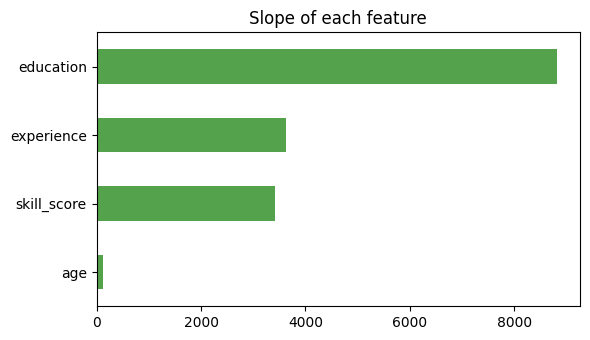

In [6]:
lr = results["LinearRegression"]["model"]

print("intercept:", round(lr.intercept_, 1))
slopes = pd.Series(lr.coef_, index=X.columns)
for n, c in slopes.items():
    print(f"{n:12s} slope = {c:.1f}")

equation = f"salary = {lr.intercept_:.0f}"
for n, c in slopes.items():
    equation += f" + ({c:.0f} x {n})"
print("\n" + equation)

slopes.sort_values().plot.barh(color="#54A24B", figsize=(6, 3.5), title="Slope of each feature")
plt.tight_layout()
plt.show()

### slope لمتغير واحد (experience فقط) باستخدام np.polyfit

experience -> salary : slope = 3700.5 , intercept = 102590.4


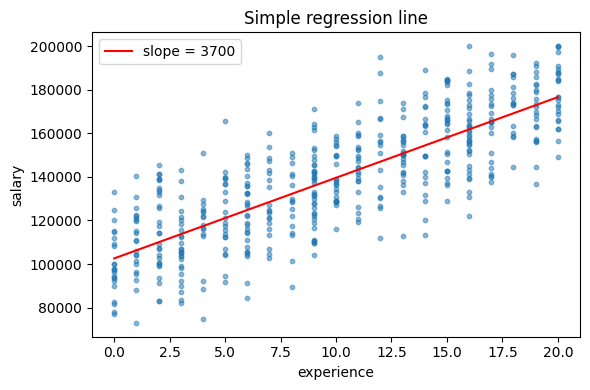

In [7]:
slope, intercept = np.polyfit(df["experience"], df["salary"], 1)
print(f"experience -> salary : slope = {slope:.1f} , intercept = {intercept:.1f}")

plt.figure(figsize=(6, 4))
plt.scatter(df["experience"], df["salary"], s=10, alpha=0.5)
xs = np.linspace(0, 20, 100)
plt.plot(xs, slope * xs + intercept, "r", label=f"slope = {slope:.0f}")
plt.xlabel("experience")
plt.ylabel("salary")
plt.legend()
plt.title("Simple regression line")
plt.tight_layout()
plt.show()

### حساب معادلة الـ slope يدوياً (بالقانون) وتوقع الراتب لـ 18 سنة خبرة

القانون: **slope = Σ(x − x̄)(y − ȳ) / Σ(x − x̄)²** ، و **intercept = ȳ − slope × x̄** ، ثم **salary = slope × x + intercept**

In [8]:
x = df["experience"].to_numpy(dtype=float)
y_ = df["salary"].to_numpy(dtype=float)

x_mean, y_mean = x.mean(), y_.mean()
slope_manual = np.sum((x - x_mean) * (y_ - y_mean)) / np.sum((x - x_mean) ** 2)
intercept_manual = y_mean - slope_manual * x_mean

print(f"x_mean = {x_mean:.3f} , y_mean = {y_mean:.1f}")
print(f"slope     = {slope_manual:.2f}")
print(f"intercept = {intercept_manual:.2f}")
print(f"\nالمعادلة: salary = {slope_manual:.2f} x experience + {intercept_manual:.2f}")

years = 18
pred_18 = slope_manual * years + intercept_manual
pred_18 = int(round(np.clip(pred_18, SAL_MIN, SAL_MAX)))
print(f"\nالراتب المتوقع لـ {years} سنة خبرة = {slope_manual:.2f} x {years} + {intercept_manual:.2f} = {pred_18}")

# تأكد أنه يطابق np.polyfit
print("يطابق polyfit؟", np.isclose(slope_manual, slope) and np.isclose(intercept_manual, intercept))

x_mean = 9.960 , y_mean = 139447.0
slope     = 3700.46
intercept = 102590.39

المعادلة: salary = 3700.46 x experience + 102590.39

الراتب المتوقع لـ 18 سنة خبرة = 3700.46 x 18 + 102590.39 = 169199
يطابق polyfit؟ True


### توقع 18 سنة خبرة بالنموذج الكامل (مع باقي المتغيرات)

In [9]:
# نفترض: ماستر (3)، مهارات 7، والعمر = 22 + 18 = 40
row = pd.DataFrame([[18, 3, 40, 7]], columns=X.columns)
full_18 = int(round(np.clip(lr.predict(row)[0], SAL_MIN, SAL_MAX)))
print("النموذج الكامل (خبرة 18، ماستر، عمر 40، مهارات 7):", full_18)

النموذج الكامل (خبرة 18، ماستر، عمر 40، مهارات 7): 178995


## 6) الحقيقي مقابل المتوقع

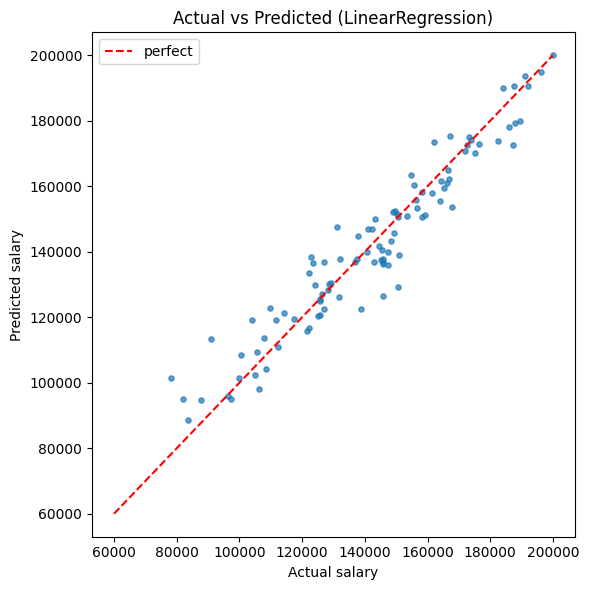

In [10]:
plt.figure(figsize=(6, 6))
plt.scatter(y_test, best["pred"], s=14, alpha=0.7)
plt.plot([SAL_MIN, SAL_MAX], [SAL_MIN, SAL_MAX], "r--", label="perfect")
plt.xlabel("Actual salary")
plt.ylabel("Predicted salary")
plt.title(f"Actual vs Predicted ({best_name})")
plt.legend()
plt.tight_layout()
plt.show()

## 7) التنبؤ براتب شخص جديد

In [11]:
def predict_salary(experience, education, age, skill_score, model=lr):
    row = pd.DataFrame([[experience, education, age, skill_score]], columns=X.columns)
    value = model.predict(row)[0]
    return int(round(np.clip(value, SAL_MIN, SAL_MAX)))

print("Predicted salary:", predict_salary(experience=5, education=3, age=30, skill_score=7))

Predicted salary: 130503
